[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


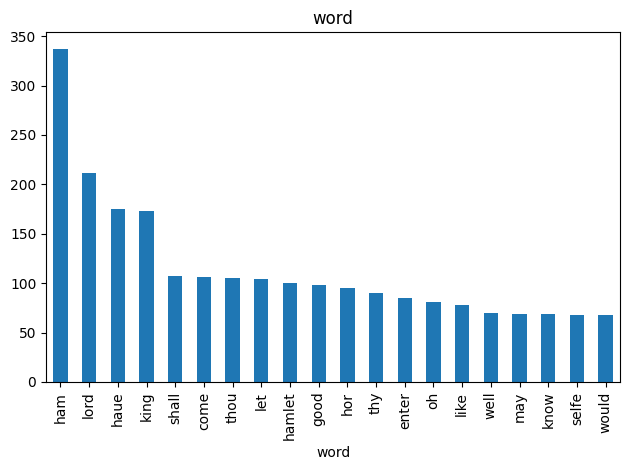

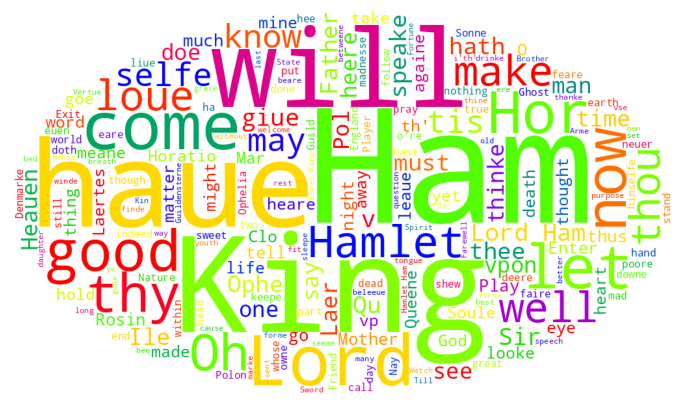

In [9]:
import matplotlib.pyplot as plt
from textblob import TextBlob
from nltk.corpus import stopwords
from operator import itemgetter
import pandas as pd
from wordcloud import WordCloud
import requests
import imageio
import nltk
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt')
nltk.download('punkt_tab')



!pip install requests

target_url ='https://www.gutenberg.org/files/2265/2265-0.txt'

response = requests.get(target_url)

data = response.text

blob=TextBlob(data)

stop_words=stopwords.words('english')

#items=blob.word_counts.items()
items=[item for item in blob.word_counts.items() if item[0] not in stop_words]

sorted_items = sorted(items,key=itemgetter(1),reverse=True)
top20=sorted_items[:20]

df=pd.DataFrame(top20,columns=['word','count'])
df.plot.bar(x='word',y='count',legend=False)
plt.title("word")
plt.gcf().tight_layout()
plt.show()


#WordCLoud


image_file="https://media.cheggcdn.com/media/216/21621ee5-e80f-47f3-9145-513f2229b390/phploeBuh.png"

mask_image =imageio.v3.imread(image_file)

wordcloud= WordCloud(colormap='prism',mask=mask_image,background_color='white')
wordcloud.generate(data)
wordcloud.to_file('Hamlet.png')

plt.figure(figsize=(10,5))
plt.imshow(wordcloud)
plt.axis('off')
plt.show()